In [1]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import numpy as np
import json

Plots

In [250]:
def draw_plots(path):
    with open(path, "r") as f:
        dic = json.load(f)
    history = dic["history"]
    batch_hist = [row for row in history if "batch_idx" in row]
    epoch_hist = [row for row in history if "batch_idx" not in row]
    bdf = pd.DataFrame(batch_hist)
    edf = pd.DataFrame(epoch_hist)
    # fractional epoch: 2.5 == halfway through epoch 2
    bdf["progress"] = bdf["epoch"] + bdf["batch_percentage"]
    # epoch-level rows are logged at the *end* of the epoch
    edf["progress"] = edf["epoch"] + 1
    has_bleu = "bleu_calculations_val" in edf

    train_c, val_c, time_c = "#2a78d6", "#eb6834", "#1baf7a"
    if has_bleu:
        fig, (ax_loss, ax_time, ax_gap,ax_non_smooth,ax_bleu) = plt.subplots(
                    5, 1, figsize=(12, 12), sharex=True, constrained_layout=True
            )
    else:
        fig, (ax_loss, ax_time, ax_gap,ax_non_smooth) = plt.subplots(
            4, 1, figsize=(12, 12), sharex=True, constrained_layout=True
        )
    fig.suptitle(f"Training run: {path}", fontsize=13)

    # 1) batch loss with epoch-level averages overlaid on the same timeline
    ax_loss.plot(bdf["progress"], bdf["batch_loss"], color=train_c, lw=1,
                 alpha=0.6, label="train loss (per batch)")
    ax_loss.plot(edf["progress"], edf["avg_loss"], color=train_c, lw=2,
                 marker="o", ms=5, label="train loss (epoch avg)")
    ax_loss.plot(edf["progress"], edf["avg_vloss"], color=val_c, lw=2,
                 marker="o", ms=5, label="val loss (epoch avg)")
    ax_loss.set_yscale("log")
    ax_loss.yaxis.set_major_formatter(ScalarFormatter())
    ax_loss.yaxis.set_minor_formatter(ScalarFormatter())
    ax_loss.set_ylabel("cross-entropy loss (log scale)")
    ax_loss.set_title("Loss")
    ax_loss.legend(loc="upper right")

    # 2) per-batch step time
    ax_time.plot(bdf["progress"], bdf["tokens/sec"], color=time_c, lw=1)
    ax_time.set_ylabel("tokens/sec")
    ax_time.set_title("tokens/sec")

    # 3) train/val gap per epoch
    ax_gap.plot(edf["progress"], edf["avg_vloss"] - edf["avg_loss"],
                color=val_c, lw=2, marker="o", ms=5)
    ax_gap.axhline(0, color="0.6", lw=1, ls="--")
    ax_gap.set_ylabel("val loss − train loss")
    ax_gap.set_title("Generalization gap (positive = val worse than train)")
    ax_gap.set_xlabel("epoch")

    # 4) batch non smoothed CE with epoch-level averages overlaid on the same timeline
    if "non_smoothed_loss_fn_val" in edf:
        ax_non_smooth.plot(edf["progress"], edf["non_smoothed_loss_fn"], color=train_c, lw=2,
                    marker="o", ms=5, label="train non smoothed CE (epoch avg)")
        ax_non_smooth.plot(edf["progress"], edf["non_smoothed_loss_fn_val"], color=val_c, lw=2,
                    marker="o", ms=5, label="val non smoothed CE (epoch avg)")
        ax_non_smooth.set_yscale("log")
        ax_non_smooth.yaxis.set_major_formatter(ScalarFormatter())
        ax_non_smooth.yaxis.set_minor_formatter(ScalarFormatter())
        ax_non_smooth.set_ylabel("cross-entropy loss (log scale)")
        ax_non_smooth.set_title("Non Smoothed Loss")
        ax_non_smooth.legend(loc="upper right")

    
    if has_bleu:
        # ax_bleu.plot(edf["progress"], edf["bleu_calculations_val"], color=train_c, lw=2,
        #             marker="o", ms=5, label="train non smoothed CE (epoch avg)")
        filtered_bleu = edf[edf["bleu_calculations_val"] > 0]
        ax_bleu.plot(filtered_bleu["progress"], filtered_bleu["bleu_calculations_val"], color=val_c, lw=2,
                    marker="o", ms=5, label="val BLEU")
        ax_bleu.yaxis.set_major_formatter(ScalarFormatter())
        ax_bleu.yaxis.set_minor_formatter(ScalarFormatter())
        ax_bleu.set_ylabel("val bleu")
        ax_bleu.set_title("BLEU")
        ax_bleu.legend(loc="upper right")

    for ax in (ax_loss, ax_time, ax_gap,ax_non_smooth):
        ax.grid(True, color="0.9", lw=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    ax_gap.set_xlim(0, edf["progress"].max())
    ax_gap.set_xticks(range(0, int(edf["progress"].max()) + 1))

    plt.show()
    return bdf, edf, batch_hist

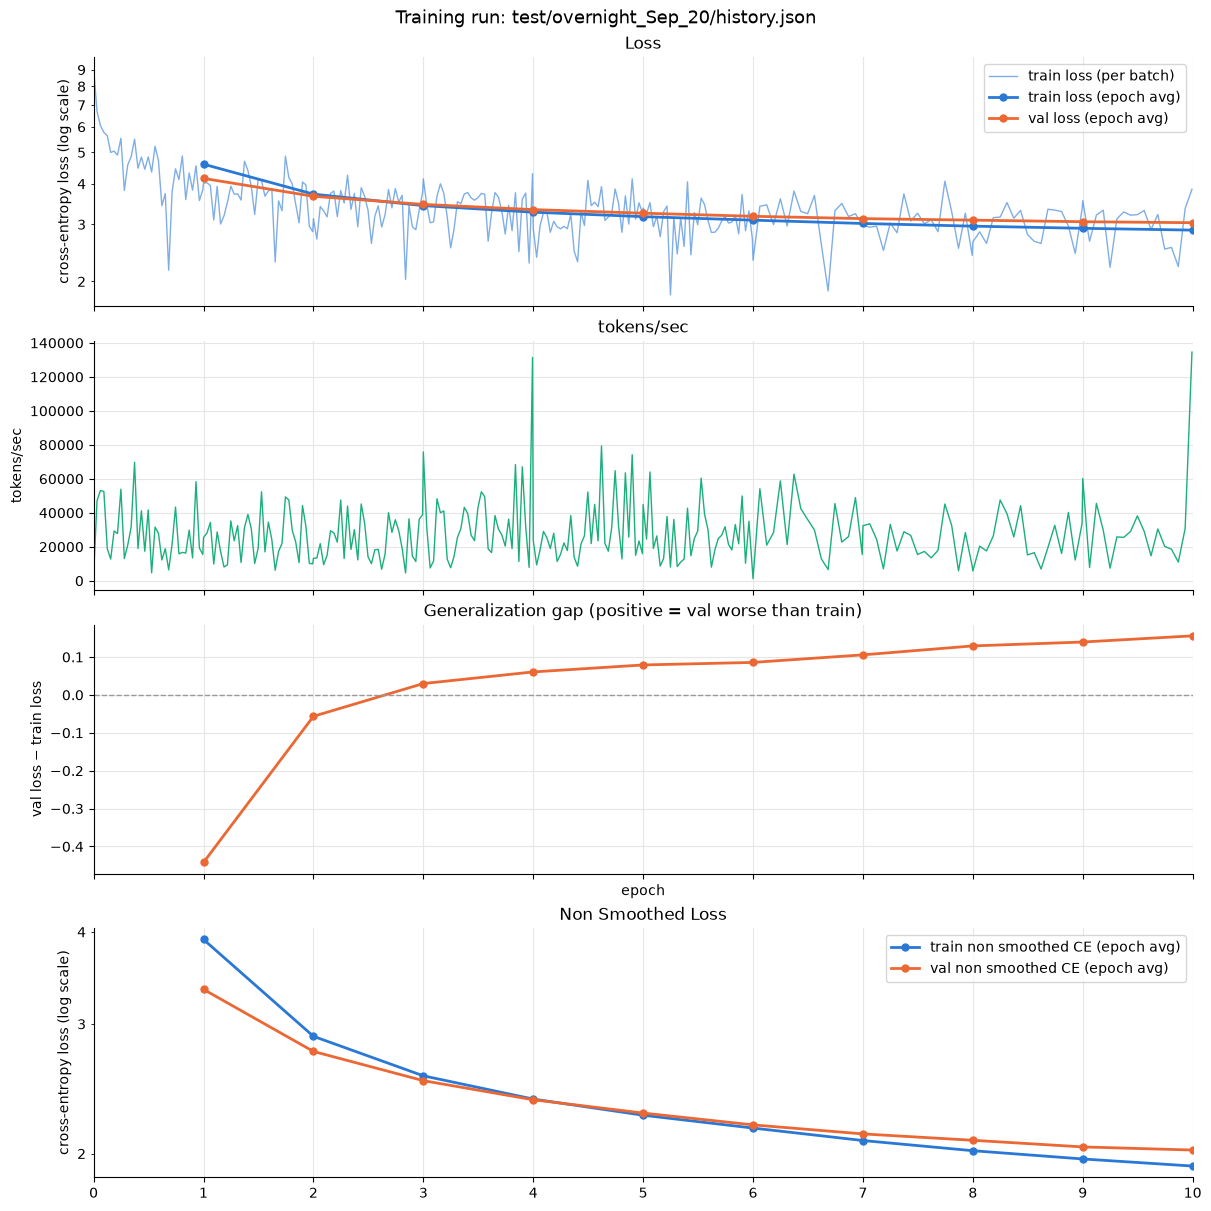

In [192]:
bdf_20,edf_20,batch_hist_20 = draw_plots("test/overnight_Sep_20/history.json")

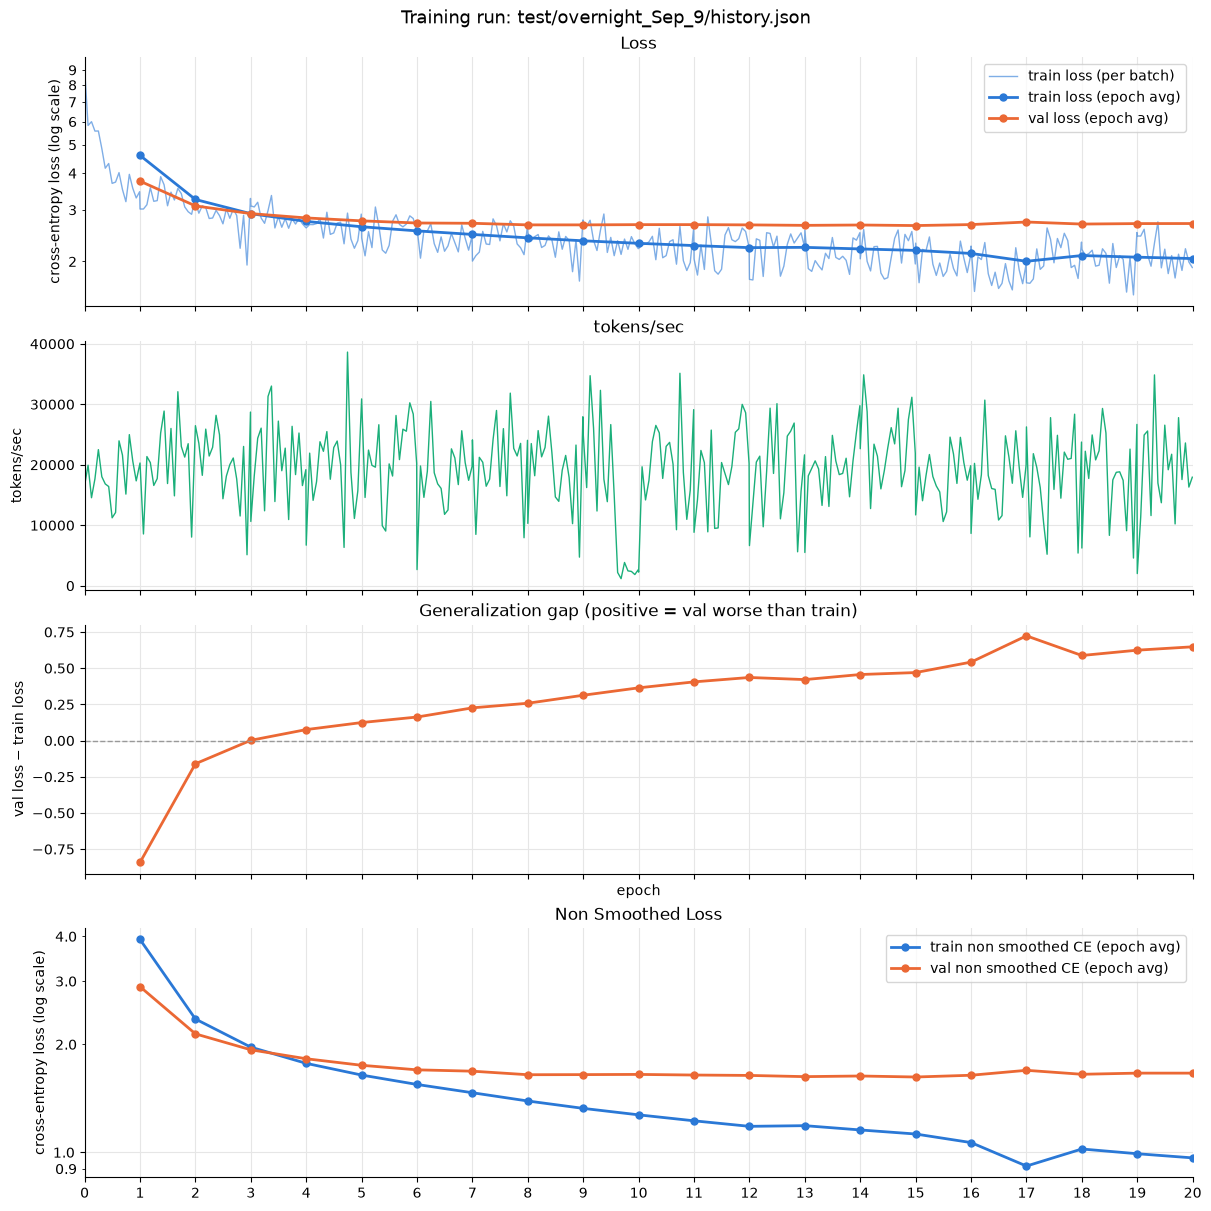

In [252]:
bdf_9,edf_9,batch_hist_9 = draw_plots("test/overnight_Sep_9/history.json")

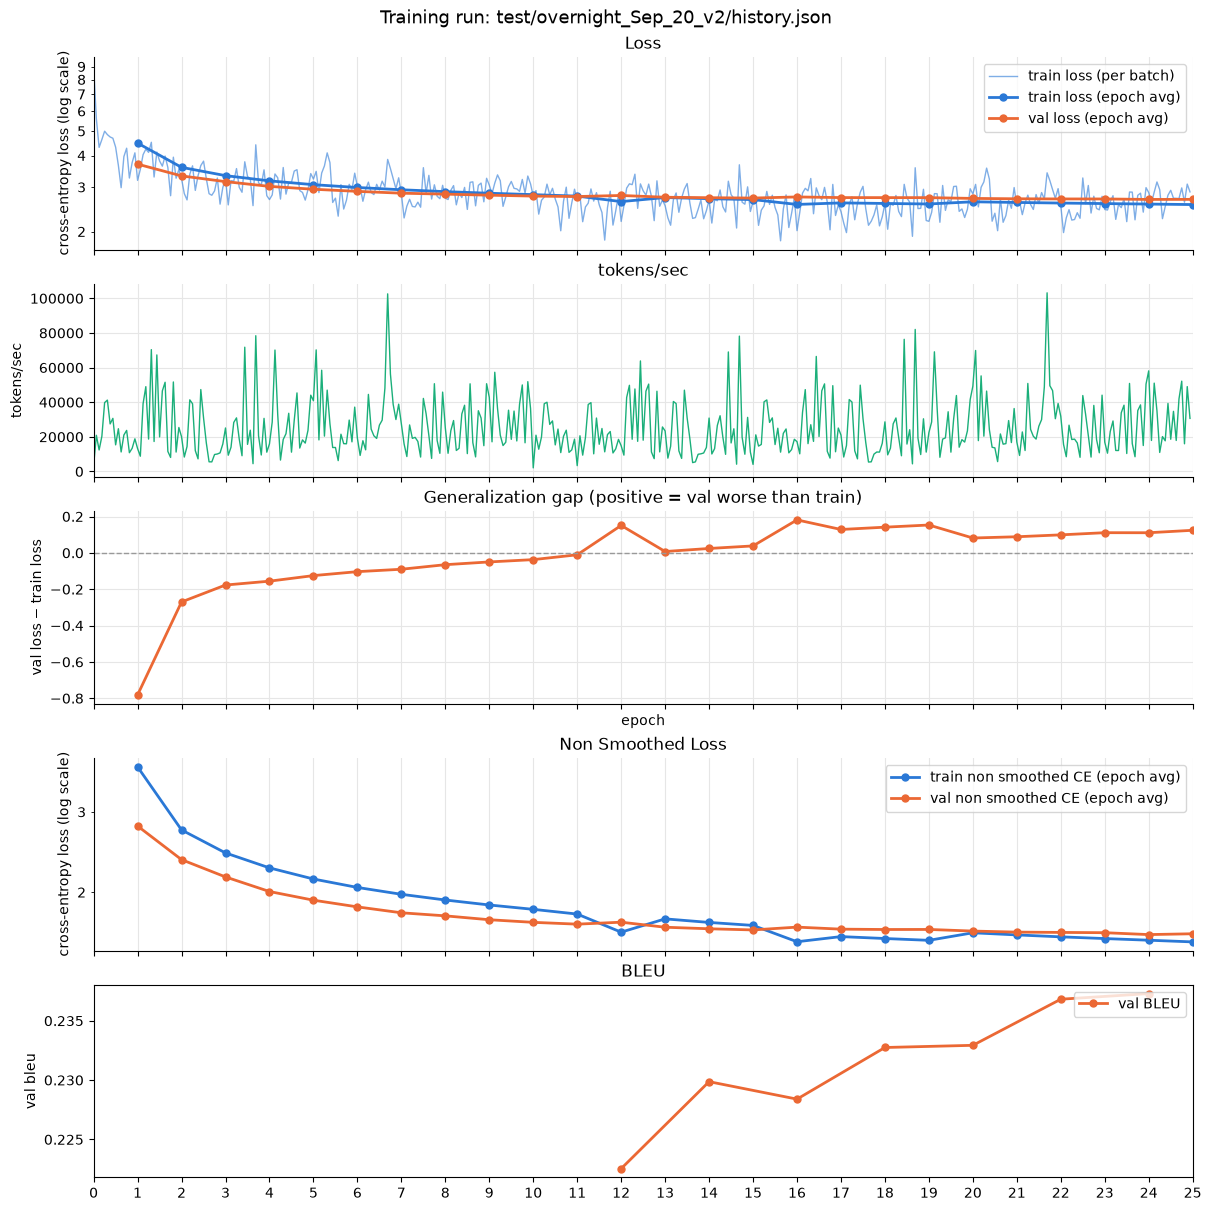

In [251]:
bdf_20_v2,edf_20_v2,batch_hist_20_v2 = draw_plots("test/overnight_Sep_20_v2/history.json")

In [228]:
edf_20_v2.tail()

,avg_loss,avg_vloss,epoch,avg_time,epoch_time,non_smoothed_loss_fn,non_smoothed_loss_fn_val,bleu_calculations,bleu_calculations_val,progress
20,2.607638,2.696302,20,0.090223,580.480067,1.611956,1.634869,0.0,0.000000,21
21,2.593525,2.692593,21,0.090170,579.365208,1.596249,1.632366,0.0,0.236816,22
22,2.581140,2.692148,22,0.090671,582.226573,1.582460,1.630072,0.0,0.000000,23
23,2.569604,2.680334,23,0.090177,579.052884,1.569374,1.614594,0.0,0.237290,24
24,2.557893,2.682125,24,0.092600,594.970062,1.556045,1.621331,0.0,0.000000,25


Decoding 

In [259]:
import sentencepiece
import torch
from torch.distributions import Categorical
from torchmetrics.text import BLEUScore,SacreBLEUScore

In [256]:
import importlib
import train
importlib.reload(train)
from train import DEVICE, config, load_best_model

In [257]:
model, _, history = load_best_model()



num_parameters: 25,634,816 - num_non_embedding_params: 22,050,816
2026-09-24 00:38:09.834505: loss_fn loaded
2026-09-24 00:38:09.834729: loading best pre saved
best model path found.
2026-09-24 00:38:13.386850: Starting from pre saved with: start_epoch: 24, best_val_loss: 2.6803, last_epoch_vloss: 2.68, non_improve_cnt: 1.00


In [267]:
sp_bpe = sentencepiece.SentencePieceProcessor()
sp_bpe.load("bpe.model")
sacreblue_metric = SacreBLEUScore(lowercase=True)
blue_metric = BLEUScore()

In [269]:
english_orig_translation = "The human brain processes visual information much faster than we previously assumed in science."
german_text = "Das menschliche Gehirn verarbeitet visuelle Informationen viel schneller, als wir bisher in der Wissenschaft angenommen haben."

german_list_enc = sp_bpe.encode_as_ids(german_text, add_bos=True, add_eos=True)
german_encoding = torch.tensor([german_list_enc]).to(DEVICE)

english_encoding = [sp_bpe.bos_id()]

i = 0
model.eval()
with torch.no_grad():
    while i < 20:
        logits = model.forward(german_encoding,torch.tensor([english_encoding]).to(DEVICE)) # B,Sy,VS
        dist = Categorical(logits=logits[0,-1,:])

        new_enc = dist.sample().item()
        english_encoding.append(new_enc)
        print(f"debug: new encoding: '{sp_bpe.decode_ids(english_encoding)}'")
        if new_enc == sp_bpe.eos_id():
            print("debug: reached EOS")
            break 
        i+=1
sacre_score = sacreblue_metric([sp_bpe.decode_ids(english_encoding)], [[english_orig_translation]])
score = blue_metric([sp_bpe.decode_ids(english_encoding)], [[english_orig_translation]])
print(f"SacreBLEU Score: {sacre_score}")
print(f"BLEU Score: {score}")

debug: new encoding: 'These'
debug: new encoding: 'These human'
debug: new encoding: 'These human brain'
debug: new encoding: 'These human brain process'
debug: new encoding: 'These human brain processes'
debug: new encoding: 'These human brain processes visual'
debug: new encoding: 'These human brain processes visual hard'
debug: new encoding: 'These human brain processes visual hard information'
debug: new encoding: 'These human brain processes visual hard information as'
debug: new encoding: 'These human brain processes visual hard information as we'
debug: new encoding: 'These human brain processes visual hard information as we''
debug: new encoding: 'These human brain processes visual hard information as we've'
debug: new encoding: 'These human brain processes visual hard information as we've been'
debug: new encoding: 'These human brain processes visual hard information as we've been doing'
debug: new encoding: 'These human brain processes visual hard information as we've been do

Batch calculations and comparing with original paper

In [ ]:
from train import load_data, lr_update_fn
import torch

In [ ]:
config["mega_batch_size"]

In [ ]:
train_loader, val_loader = load_data()

In [ ]:
total_x = 0
total_y = 0
x_len=0
y_len=0

pad_tokens = 0
for X,Y in train_loader: # B,Sy
    cur_x = torch.sum(X != config["pad_token"])
    cur_y = torch.sum(Y != config["pad_token"])
    pad_tokens += X.shape[0] * (X.shape[1] + Y.shape[1]) - cur_x - cur_y
    total_x+=cur_x
    total_y+=cur_y

    x_len+=X.shape[1]
    y_len+=Y.shape[1]

In [ ]:
print(f"total_x: {total_x.item():,}")
print(f"total_y: {total_y.item():,}")
print(f"total_pad_tokens: {pad_tokens.item():,}")

print("per step: ")
print(f"total_x: {total_x / len(train_loader):,.2f}")
print(f"total_y: {total_y / len(train_loader):,.2f}")
print(f"pad_tokens: {pad_tokens / len(train_loader) / 2:,.2f}")
print(f"X_len: {x_len / len(train_loader):.2f}")
print(f"Y_len: {y_len / len(train_loader):.2f}")

In [ ]:
batches_per_epoch_me = 3221 # from logs/output_logs_overnight_Sep_5_2.txt
num_epochs_me = 15
sent_len_me = (x_len + y_len)/(2*len(train_loader))
sent_len_them = sent_len_me #??
print(f"tokens seen total: {100_000 * 25_000:,} - {(total_x) * num_epochs_me:,}")
print(f"tokens/batch:      {25_000:,} - {(total_x + total_y)/len(train_loader):,.0f}")
print(f"tokens/epoch:      {4_500_000 * sent_len_them:,.0f} - {total_x + total_y:,}") # assuming they have the same sentence length as us
print(f"batches/epoch:     {(4_500_000 * sent_len_them / 25_000):,.0f} - {batches_per_epoch_me:,}") # batches_t * tokens/epoch / tokens_t
print(f"epochs:            {100_000 / ((4_500_000 * sent_len_them / 25_000)):.1f} - {num_epochs_me}")
print(f"batches:           {100_000:,} - {batches_per_epoch_me * num_epochs_me:,.2f}")

took back: 

- higher tokens/batch than paper -> less gradient noise. Hence better. 
- batches/epoch is half -> Noam LR is still warming up at the start
- total batches is third -> Noam LR is not fully calmed down yet at the end -> lower warmup_steps. 
- 

Calculating BLEU

In [270]:
import importlib
import train
importlib.reload(train)
from train import calculate_bleu, load_best_model, load_data

In [219]:
# train_loader, val_loader = load_data()

In [209]:
model, _, history = load_best_model()



num_parameters: 25,634,816 - num_non_embedding_params: 22,050,816
2026-09-21 23:19:51.963894: loss_fn loaded
2026-09-21 23:19:51.963925: loading best pre saved
best model path found.
2026-09-21 23:19:52.219449: Starting from pre saved with: start_epoch: 9, best_val_loss: 3.0355, last_epoch_vloss: 3.04, non_improve_cnt: 0.00


In [ ]:
gen = calculate_bleu(val_loader,model,sp_bpe,return_translations=True) 
# sep_20: 20.44
# sep_20_v2: 22.1 - filtered data
# Sep 22: 23.7 (epoch 15)
# sep_9: 25.51 - more data and bigger epoch. 

2026-09-24 00:43:20.975264 started calculating bleu
2026-09-24 00:43:49.424553 finished calculating bleu - avg bleu: 28.66 - total_time: 28.449207067489624 - avg_eos_idx: 27.20


In [239]:
gen

tensor(0.2373)

Data Filtering

In [127]:
NUM_TOKENS=0
val_df = pd.read_csv("val_sorted_df.csv")
def encode(item):
        global NUM_TOKENS
        ids = sp_bpe.encode_as_ids(item, add_bos=True, add_eos=True)
        NUM_TOKENS+=len(ids)
        return np.array(ids, dtype=np.int64)
# filter based on ratio. 
val_df['x_enc'] = [len(encode(item)) for item in val_df["entext"]]
# val_df["detext"] = val_df["detext"].str.replace("<br","")
# sorted_df = val_df.sort_values("x_enc").reset_index().drop(columns=["Unnamed: 0", "x_enc", "level_0"])
# sorted_df.to_csv("val_sorted_df.csv",index=False)
print(NUM_TOKENS)

27474


In [126]:
val_df.iloc[-1,4]

"What makes ayahuasca fascinating  is not the sheer pharmacological potential of this preparation,  but the elaboration of it. It's made really of two different sources:  on the one hand, this woody liana  which has in it a series of beta-carbolines,  harmine, harmaline, mildly hallucinogenic --  to take the vine alone  is rather to have sort of blue hazy smoke  drift across your consciousness --  but it's mixed with the leaves of a shrub in the coffee family"

In [170]:
NUM_TOKENS=0
train_df = pd.read_csv("train_filtered_df.csv").drop(columns=["Unnamed: 0"])
def encode(item):
        global NUM_TOKENS
        ids = sp_bpe.encode_as_ids(item, add_bos=True,add_eos=True)
        NUM_TOKENS+=len(ids)
        return np.array(ids, dtype=np.int64)
# train_df["detext"] = train_df["detext"].str.replace("<br","")
# Remove anything between [...] and ♪ and long sentences. 
train_df['x_enc'] = [len(encode(item)) for item in train_df["entext"]]
train_df['y_enc'] = [len(encode(item)) for item in train_df["detext"]]
train_df["ratio"] = train_df["x_enc"] / train_df["y_enc"]
print(NUM_TOKENS)

11517829


In [ ]:
en_value_counts = train_df.groupby("entext")["entext"].transform("count")
de_value_counts = train_df.groupby("detext")["detext"].transform("count")
en_counter = train_df.groupby("entext").cumcount()
de_counter = train_df.groupby("detext").cumcount()
mask = (
    ((en_value_counts < 10) | (en_counter < 5)) & 
    ((de_value_counts < 10) | (de_counter < 5)) & 
    (train_df["x_enc"] >= 4) & 
    (train_df["y_enc"] > 4) & 
    (train_df["ratio"] >= 0.4) & 
    (train_df["ratio"] <= 2.5)
)
filtered_df = train_df[mask]

In [ ]:
filtered_df.head()

In [ ]:
filtered_df.drop(columns=["Unnamed: 0","x_enc","y_enc","ratio"]).to_csv("train_filtered_df.csv")

In [ ]:
mask.value_counts()